# AI Smart Agriculture — Satellite Land-Use Analysis
## Milestone 1 (redo) + Milestone 2: Advanced Data Analysis & Feature Engineering

**Research question.** *Can we tell agricultural land apart from other land types using only
Sentinel-2 satellite images — and which visual features (color, vegetation, texture) carry
that signal?*

**Why it matters.** Knowing where cropland, pasture and natural vegetation are — and how they
differ — is the first step for crop monitoring, land planning and yield estimation at scale.
Satellite images cover every field, every few days, for free.

**Dataset.** [EuroSAT](https://github.com/phelber/EuroSAT) — 27,000 labeled Sentinel-2 RGB
image patches (64×64 px, 10 m/pixel ≈ 640 m × 640 m of ground each), 10 land-use classes.
4 of the 10 classes are agricultural/vegetation: *AnnualCrop, PermanentCrop, Pasture,
HerbaceousVegetation*.

| Part | What it covers |
|---|---|
| **A. Milestone 1 (redo)** | Data collection, quality audit, EDA, preprocessing & splits |
| **B. Milestone 2** | Feature engineering, statistical tests, correlation, feature selection, PCA / t-SNE, expected impact on model performance |

Runs locally (Apple Silicon / CPU) or on Google Colab (GPU) — no manual downloads.

In [1]:
# Colab: everything needed is preinstalled except possibly scikit-image
import importlib.util, subprocess, sys
for pkg, mod in [("scikit-image", "skimage"), ("seaborn", "seaborn")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

In [2]:
import hashlib, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy import stats
import torch, torchvision
from torchvision.datasets import EuroSAT

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

DEVICE = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", DEVICE)

DATA_DIR = Path("data")
FIG_DIR = Path("outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR = Path("outputs/tables");  TAB_DIR.mkdir(parents=True, exist_ok=True)

# Chart styling: one blue for single-series charts; green marks the agricultural classes.
BLUE, GREEN, GRAY = "#2a78d6", "#008300", "#c3c2b7"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": GRAY, "grid.color": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.titleweight": "bold",
    "axes.titlesize": 12, "figure.dpi": 110, "savefig.dpi": 160,
    "savefig.bbox": "tight", "font.size": 10})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", facecolor="white")
    plt.show()

PyTorch 2.14.1 | device: mps


---
# Part A — Milestone 1 (redo): Collection, Audit, EDA, Preprocessing
## A1. Data collection
`torchvision` downloads the official EuroSAT RGB release (~94 MB) on first run.

In [3]:
ds = EuroSAT(root=str(DATA_DIR), download=True)
CLASSES = ds.classes
AGRI = ["AnnualCrop", "PermanentCrop", "Pasture", "HerbaceousVegetation"]
GROUP = {c: ("Agriculture" if c in AGRI else
             "Water" if c in ("River", "SeaLake") else
             "Forest" if c == "Forest" else "Built-up") for c in CLASSES}

df = pd.DataFrame(ds.samples, columns=["path", "label"])
df["cls"] = df["label"].map(dict(enumerate(CLASSES)))
df["group"] = df["cls"].map(GROUP)
print(f"{len(df):,} images, {len(CLASSES)} classes")
df.head()

27,000 images, 10 classes


,path,label,cls,group
0,data/eurosat/2750/AnnualCrop/AnnualCrop_1.jpg,0,AnnualCrop,Agriculture
1,data/eurosat/2750/AnnualCrop/AnnualCrop_10.jpg,0,AnnualCrop,Agriculture
2,data/eurosat/2750/AnnualCrop/AnnualCrop_100.jpg,0,AnnualCrop,Agriculture
3,data/eurosat/2750/AnnualCrop/AnnualCrop_1000.jpg,0,AnnualCrop,Agriculture
4,data/eurosat/2750/AnnualCrop/AnnualCrop_1001.jpg,0,AnnualCrop,Agriculture


## A2. Data quality audit
Before changing anything, measure what is actually wrong: unreadable files, wrong sizes /
modes, exact duplicate images, and fully blank (all one color) tiles.

In [4]:
t0 = time.time()
imgs, sizes, modes, md5s, bad = [], [], [], [], []
for i, p in enumerate(df["path"]):
    try:
        raw = Path(p).read_bytes()
        im = Image.open(p); im.load()
        sizes.append(im.size); modes.append(im.mode)
        arr = np.asarray(im.convert("RGB"), dtype=np.uint8)
        imgs.append(arr)
        md5s.append(hashlib.md5(arr.tobytes()).hexdigest())
    except Exception as e:
        bad.append((i, repr(e))); imgs.append(None); sizes.append(None); modes.append(None); md5s.append(None)

df["size"], df["mode"], df["pixel_md5"] = sizes, modes, md5s
X = np.stack(imgs)                      # (N, 64, 64, 3) uint8, kept in RAM (~330 MB)
flat_std = X.reshape(len(X), -1).std(axis=1)

audit = pd.Series({
    "unreadable files": len(bad),
    "images not 64x64": int((df["size"] != (64, 64)).sum()),
    "images not RGB": int((df["mode"] != "RGB").sum()),
    "exact duplicate images": int(df["pixel_md5"].duplicated().sum()),
    "blank / constant tiles": int((flat_std < 1.0).sum()),
}, name="count")
print(f"Loaded in {time.time()-t0:.1f}s, array {X.shape}, {X.nbytes/1e6:.0f} MB")
audit.to_frame()

Loaded in 6.3s, array (27000, 64, 64, 3), 332 MB


,count
unreadable files,0
images not 64x64,0
images not RGB,0
exact duplicate images,0
blank / constant tiles,0


In [5]:
dups = df[df["pixel_md5"].duplicated(keep=False)].sort_values("pixel_md5")
if len(dups):
    print("Duplicate groups:"); display(dups[["path", "cls", "pixel_md5"]])
    # Keep the first copy of each duplicate so the same image can't land in both train and test
    keep = ~df["pixel_md5"].duplicated(keep="first")
    df, X = df[keep].reset_index(drop=True), X[keep.values]
print("Images after de-duplication:", len(df))

Images after de-duplication: 27000


## A3. Exploratory data analysis
### Class balance

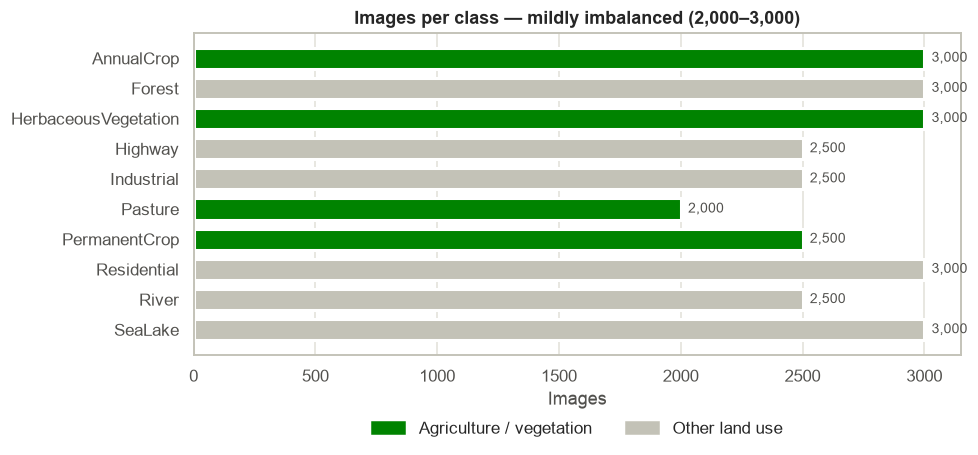

Imbalance ratio (max/min): 1.50


In [6]:
counts = df["cls"].value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(counts.index, counts.values, color=[GREEN if c in AGRI else GRAY for c in counts.index],
        height=0.7, edgecolor="white", linewidth=2)
for y, v in enumerate(counts.values):
    ax.text(v + 30, y, f"{v:,}", va="center", color=INK2, fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("Images"); ax.grid(axis="y", visible=False)
ax.set_title("Images per class — mildly imbalanced (2,000–3,000)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=GREEN, label="Agriculture / vegetation"), Patch(color=GRAY, label="Other land use")],
          loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
save(fig, "01_class_distribution")
print(f"Imbalance ratio (max/min): {counts.max()/counts.min():.2f}")

### What does each class look like?

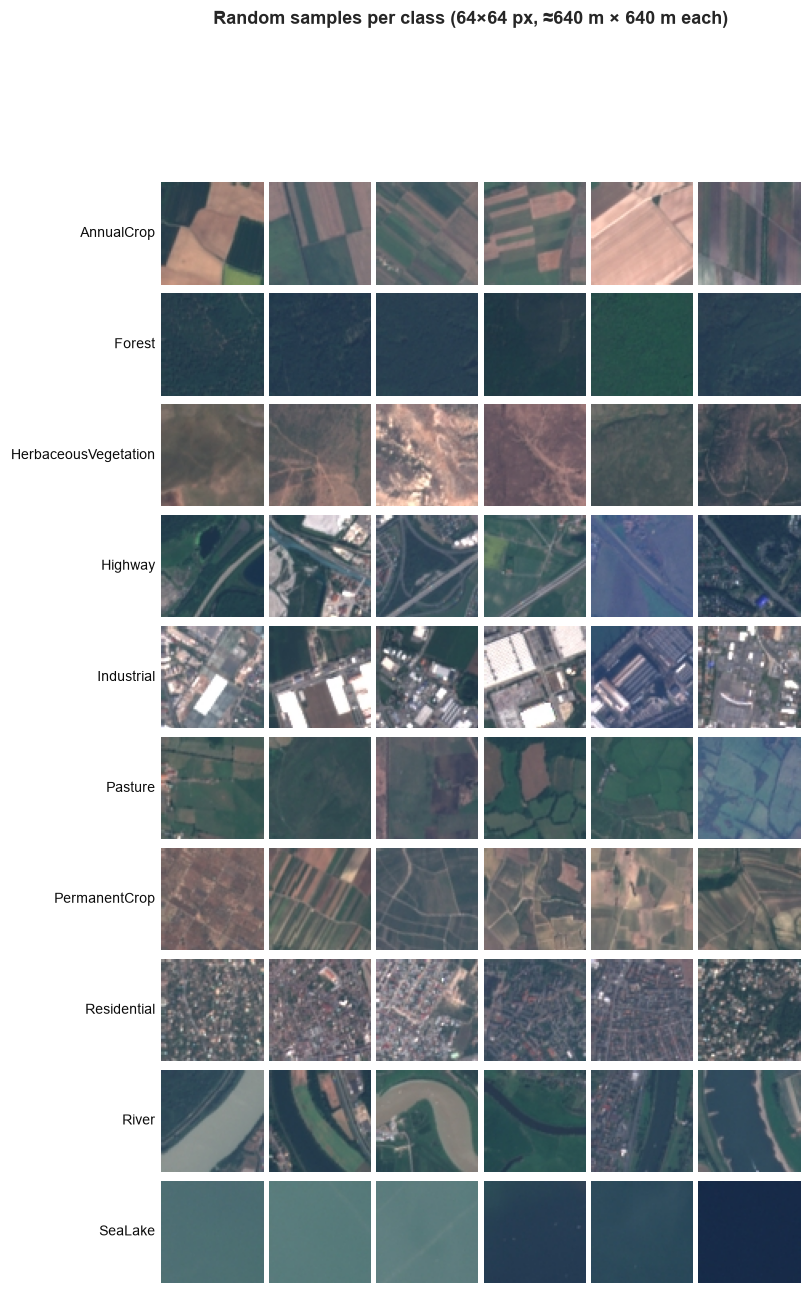

In [7]:
n_per = 6
fig, axes = plt.subplots(len(CLASSES), n_per, figsize=(n_per * 1.25, len(CLASSES) * 1.3))
for r, c in enumerate(CLASSES):
    idx = rng.choice(np.where(df["cls"] == c)[0], n_per, replace=False)
    for k, j in enumerate(idx):
        ax = axes[r, k]; ax.imshow(X[j]); ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values(): s.set_visible(False)
        if k == 0: ax.set_ylabel(c, rotation=0, ha="right", va="center", fontsize=9, color=INK)
fig.suptitle("Random samples per class (64×64 px, ≈640 m × 640 m each)", fontweight="bold", y=1.0)
plt.subplots_adjust(wspace=0.05, hspace=0.08)
save(fig, "02_sample_grid")

### The "average" image of each class
Averaging all images of a class removes individual detail and leaves its typical color.
Water is dark blue, forest dark green, crops and pasture lighter green/brown, built-up gray.

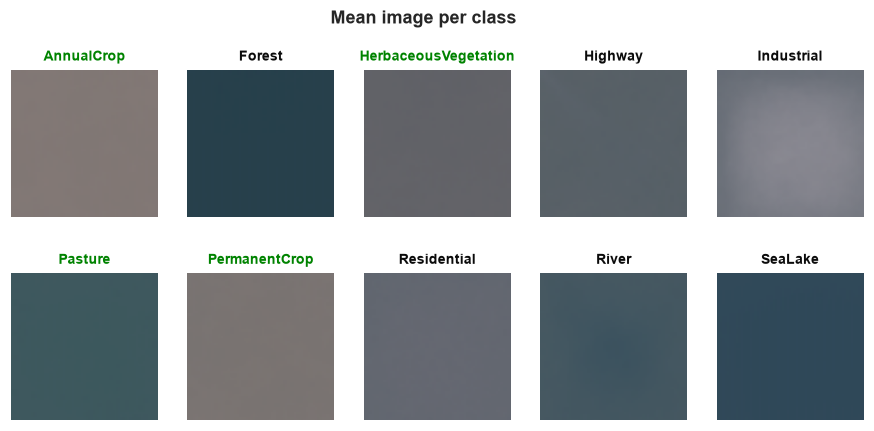

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.4))
for ax, c in zip(axes.flat, CLASSES):
    ax.imshow(X[df["cls"].values == c].mean(axis=0).astype(np.uint8))
    ax.set_title(c, fontsize=9, color=GREEN if c in AGRI else INK, fontweight="bold")
    ax.axis("off")
fig.suptitle("Mean image per class", fontweight="bold")
save(fig, "03_mean_images")

### Pixel intensity per color channel
How bright is each channel (R, G, B) in each class? Computed on a 300-image sample per class.

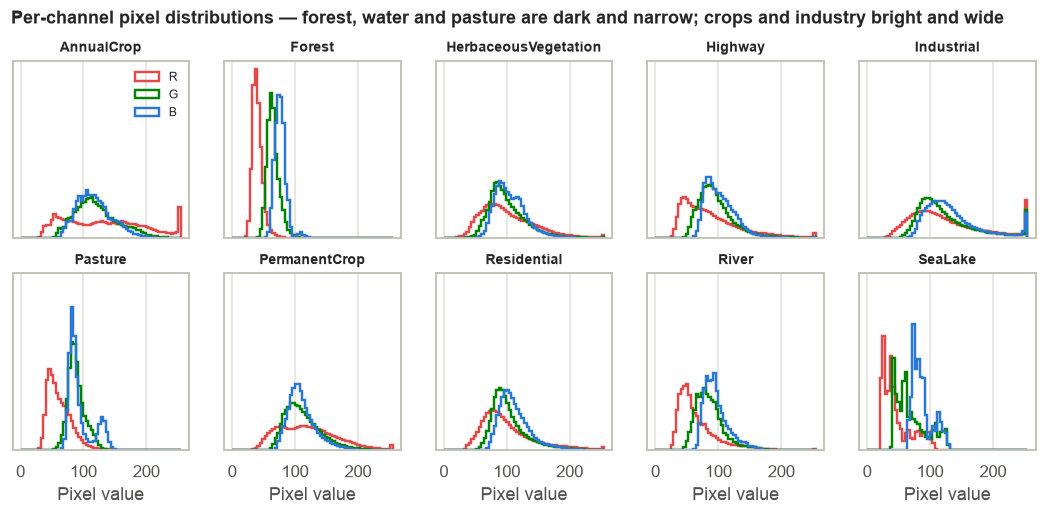

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(12, 4.6), sharex=True, sharey=True)
chan_cols = ["#e34948", "#008300", "#2a78d6"]
for ax, c in zip(axes.flat, CLASSES):
    idx = rng.choice(np.where(df["cls"] == c)[0], 300, replace=False)
    for ch, (name, col) in enumerate(zip("RGB", chan_cols)):
        ax.hist(X[idx, :, :, ch].ravel(), bins=64, range=(0, 255), histtype="step",
                color=col, linewidth=1.6, density=True, label=name)
    ax.set_title(c, fontsize=9); ax.set_yticks([])
axes[0, 0].legend(frameon=False, fontsize=8)
for ax in axes[1]: ax.set_xlabel("Pixel value")
fig.suptitle("Per-channel pixel distributions — forest, water and pasture are dark and narrow; crops and industry bright and wide",
             fontweight="bold")
save(fig, "04_channel_histograms")

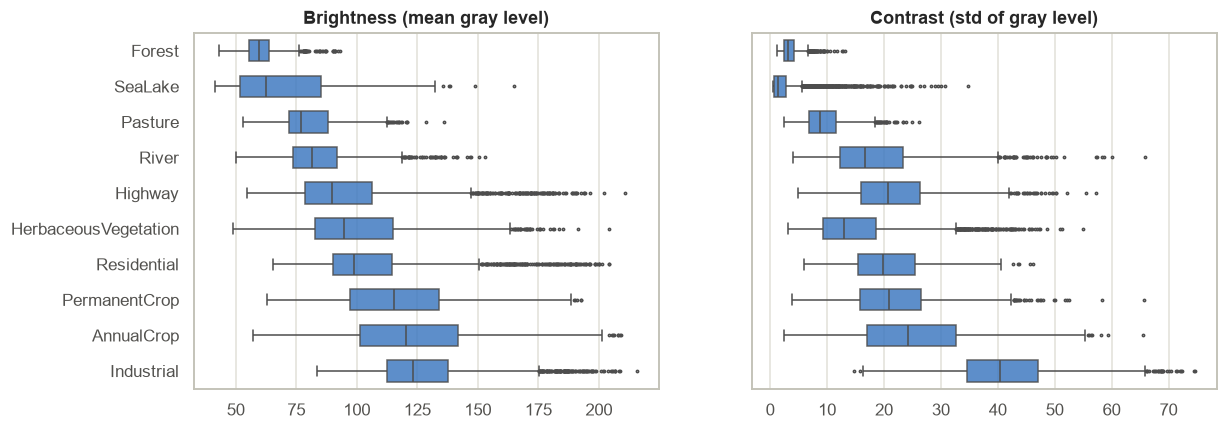

cls,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
brightness,120.3,59.5,94.7,89.9,123.1,77.1,115.2,98.8,81.6,62.5
contrast,24.2,3.2,13.0,20.7,40.4,8.8,20.8,19.8,16.7,1.3


In [10]:
gray_all = X.mean(axis=3)
df["brightness"] = gray_all.mean(axis=(1, 2))
df["contrast"]   = gray_all.std(axis=(1, 2))
order = df.groupby("cls")["brightness"].median().sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, col, title in [(axes[0], "brightness", "Brightness (mean gray level)"),
                       (axes[1], "contrast", "Contrast (std of gray level)")]:
    sns.boxplot(data=df, y="cls", x=col, order=order, ax=ax, color=BLUE, width=0.6,
                fliersize=1.5, linewidth=1, boxprops=dict(alpha=0.85))
    ax.set_title(title); ax.set_ylabel(""); ax.set_xlabel("")
save(fig, "05_brightness_contrast")
df.groupby("cls")[["brightness", "contrast"]].median().round(1).T

**EDA findings**
- Classes are only mildly imbalanced → stratified splits are enough; no resampling needed.
- Color alone separates the extremes (water, forest vs. built-up) but the four agricultural
  classes overlap heavily in brightness and channel distribution — that's the hard part.
- Brightness and contrast differ between classes, but within-class spread is large (seasons,
  regions, haze) → we need richer features than raw color.

## A4. Preprocessing
1. **Stratified split 70 / 15 / 15** (train / validation / test) — every class keeps its share.
   The **test set is not touched** in this milestone; we compare features on validation only.
2. **Normalization statistics** computed on **train only** (no leakage).
3. **Augmentation** for later model training: flips and 90° rotations are realistic for
   satellite images (there is no "up" in a top-down view).

In [11]:
from sklearn.model_selection import train_test_split
idx_all = np.arange(len(df))
idx_tr, idx_tmp = train_test_split(idx_all, test_size=0.30, stratify=df["label"], random_state=SEED)
idx_va, idx_te = train_test_split(idx_tmp, test_size=0.50, stratify=df["label"].values[idx_tmp], random_state=SEED)
df["split"] = "train"; df.loc[idx_va, "split"] = "val"; df.loc[idx_te, "split"] = "test"
df[["path", "cls", "split"]].to_csv(TAB_DIR / "splits.csv", index=False)

mean = (X[idx_tr] / 255.0).mean(axis=(0, 1, 2)); std = (X[idx_tr] / 255.0).std(axis=(0, 1, 2))
print("Split sizes:", df["split"].value_counts().to_dict())
print("Train channel mean (R,G,B):", mean.round(4), "| std:", std.round(4))
pd.crosstab(df["cls"], df["split"], normalize="columns").round(3).loc[CLASSES]

Split sizes: {'train': 18900, 'val': 4050, 'test': 4050}
Train channel mean (R,G,B): [0.3439 0.38   0.4075] | std: [0.2024 0.1367 0.1154]


split,test,train,val
cls,,,
AnnualCrop,0.111,0.111,0.111
Forest,0.111,0.111,0.111
HerbaceousVegetation,0.111,0.111,0.111
Highway,0.093,0.093,0.093
Industrial,0.093,0.093,0.093
Pasture,0.074,0.074,0.074
PermanentCrop,0.093,0.093,0.093
Residential,0.111,0.111,0.111
River,0.093,0.093,0.093


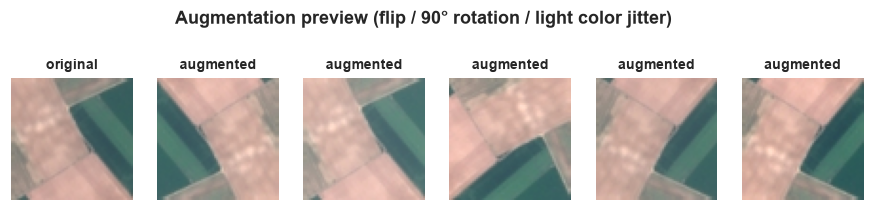

In [12]:
import torchvision.transforms.v2 as T
augment = T.Compose([T.ToImage(), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                     T.RandomChoice([T.RandomRotation((a, a)) for a in (0, 90, 180, 270)]),
                     T.ColorJitter(brightness=0.15, contrast=0.15)])
j = int(np.where(df["cls"] == "AnnualCrop")[0][3])
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
axes[0].imshow(X[j]); axes[0].set_title("original", fontsize=9)
for ax in axes[1:]:
    ax.imshow(augment(Image.fromarray(X[j])).permute(1, 2, 0).numpy()); ax.set_title("augmented", fontsize=9)
for ax in axes: ax.axis("off")
fig.suptitle("Augmentation preview (flip / 90° rotation / light color jitter)", fontweight="bold", y=1.08)
save(fig, "06_augmentation")

---
# Part B — Milestone 2: Advanced Data Analysis & Feature Engineering

A model only learns from what its inputs can express. Here we turn each image into a set of
**interpretable numeric features**, test statistically which ones distinguish land types,
remove redundancy, and measure how much each feature family would help a classifier.

## B1. Feature engineering — 23 hand-crafted features per image

| Family | Features | Why |
|---|---|---|
| **Color** | mean & std of R, G, B; saturation & value (HSV) | Water/forest/built-up have distinct colors |
| **Vegetation indices** (from RGB) | ExG (excess green), VARI, GLI, green-cover fraction | Standard agronomy indices for how green / vegetated a surface is — the core agricultural signal |
| **Water index** | blue ratio | Water reflects relatively more blue |
| **Texture** | GLCM contrast, homogeneity, energy, correlation; edge strength; LBP entropy; gray entropy | Crop fields are regular stripes, forests rough, water smooth, cities edgy |
| **Brightness** | brightness, contrast | Overall reflectance |

> EuroSAT RGB has no near-infrared band, so we use RGB vegetation indices
> (ExG, VARI, GLI) instead of NDVI. These are widely used in drone/RGB crop monitoring.

In [13]:
from skimage.color import rgb2hsv, rgb2gray
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from skimage.filters import sobel
from skimage.measure import shannon_entropy

EPS = 1e-6
ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]

def extract_features(img):
    x = img.astype(np.float32) / 255.0
    r, g, b = x[..., 0], x[..., 1], x[..., 2]
    s = r + g + b + EPS
    rn, gn, bn = r / s, g / s, b / s                 # chromatic coordinates (illumination-robust)
    exg = 2 * gn - rn - bn                           # Excess Green index
    vari = np.clip((g - r) / (g + r - b + EPS), -1, 1)  # Visible Atmospherically Resistant Index
    gli = (2 * g - r - b) / (2 * g + r + b + EPS)    # Green Leaf Index
    hsv = rgb2hsv(x)
    gray = rgb2gray(x)
    g8 = (gray * 255).astype(np.uint8)
    glcm = graycomatrix(g8 // 8, [1], ANGLES, levels=32, symmetric=True, normed=True)
    lbp = local_binary_pattern(g8, P=8, R=1, method="uniform")
    h, _ = np.histogram(lbp, bins=10, range=(0, 10)); h = h / h.sum()
    return {
        "r_mean": r.mean(), "g_mean": g.mean(), "b_mean": b.mean(),
        "r_std": r.std(), "g_std": g.std(), "b_std": b.std(),
        "sat_mean": hsv[..., 1].mean(), "val_mean": hsv[..., 2].mean(),
        "exg_mean": exg.mean(), "exg_std": exg.std(), "green_cover": (exg > 0.05).mean(),
        "vari_mean": vari.mean(), "gli_mean": gli.mean(), "blue_ratio": bn.mean(),
        "glcm_contrast": graycoprops(glcm, "contrast").mean(),
        "glcm_homogeneity": graycoprops(glcm, "homogeneity").mean(),
        "glcm_energy": graycoprops(glcm, "energy").mean(),
        "glcm_correlation": graycoprops(glcm, "correlation").mean(),
        "edge_strength": sobel(gray).mean(),
        "lbp_entropy": -(h[h > 0] * np.log2(h[h > 0])).sum(),
        "gray_entropy": shannon_entropy(g8),
        "brightness": gray.mean(), "contrast": gray.std(),
    }

t0 = time.time()
F = pd.DataFrame([extract_features(im) for im in X])
F["glcm_correlation"] = F["glcm_correlation"].fillna(1.0)   # constant patch → perfectly correlated
FEATS = list(F.columns)
print(f"{len(FEATS)} features × {len(F):,} images in {time.time()-t0:.0f}s")
F.assign(cls=df["cls"].values, split=df["split"].values).to_csv(TAB_DIR / "handcrafted_features.csv", index=False)
F.describe().T.round(3)

23 features × 27,000 images in 28s


,count,mean,std,min,25%,50%,75%,max
r_mean,27000.0,0.344,0.169,0.087,0.210,0.316,0.448,0.995
g_mean,27000.0,0.380,0.111,0.149,0.307,0.366,0.447,0.821
b_mean,27000.0,0.408,0.091,0.224,0.335,0.397,0.468,0.802
r_std,27000.0,0.091,0.065,0.002,0.038,0.083,0.135,0.357
g_std,27000.0,0.065,0.048,0.002,0.028,0.056,0.092,0.280
b_std,27000.0,0.055,0.044,0.003,0.020,0.046,0.078,0.274
sat_mean,27000.0,0.296,0.152,0.034,0.169,0.263,0.414,0.724
val_mean,27000.0,0.434,0.123,0.224,0.339,0.408,0.501,0.995
exg_mean,27000.0,0.020,0.060,-0.119,-0.022,0.011,0.055,0.339
exg_std,27000.0,0.034,0.020,0.004,0.019,0.030,0.045,0.162


### What a vegetation index "sees"
ExG highlights green vegetation. Below: one image per vegetation class and its ExG map
(dark green = strong vegetation).

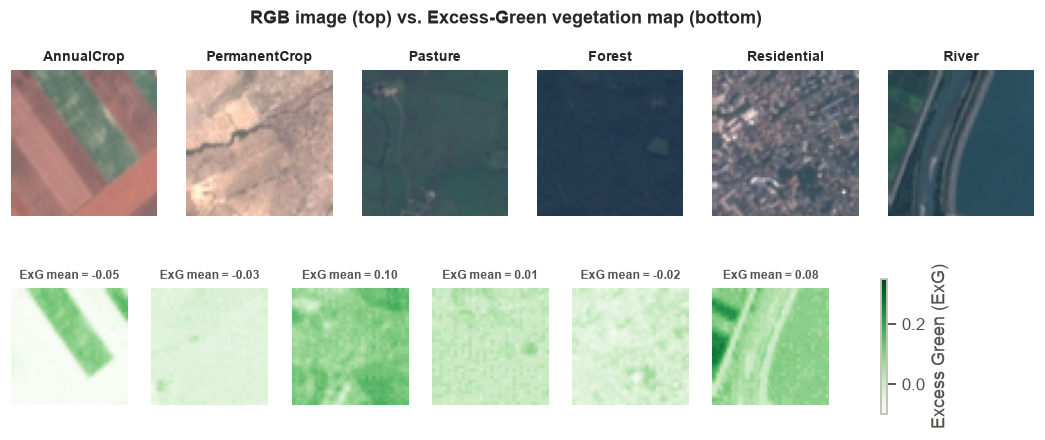

In [14]:
show = ["AnnualCrop", "PermanentCrop", "Pasture", "Forest", "Residential", "River"]
fig, axes = plt.subplots(2, len(show), figsize=(12, 4.4))
for k, c in enumerate(show):
    j = int(np.where(df["cls"] == c)[0][7])
    x = X[j].astype(np.float32) / 255; s = x.sum(axis=2) + EPS
    exg = (2 * x[..., 1] - x[..., 0] - x[..., 2]) / s
    axes[0, k].imshow(X[j]); axes[0, k].set_title(c, fontsize=9, fontweight="bold")
    im = axes[1, k].imshow(exg, cmap="Greens", vmin=-0.1, vmax=0.35)
    axes[1, k].set_title(f"ExG mean = {exg.mean():.2f}", fontsize=8, color=INK2)
for ax in axes.flat: ax.axis("off")
fig.colorbar(im, ax=axes[1, :], shrink=0.8, label="Excess Green (ExG)")
fig.suptitle("RGB image (top) vs. Excess-Green vegetation map (bottom)", fontweight="bold")
save(fig, "07_vegetation_index_maps")

## B2. Feature transformation & scaling
- Strongly skewed features (|skew| > 1) get a **Yeo-Johnson power transform** (fit on train),
  which pulls in long tails on either side — unlike `log`, it also fixes *left* skew.
- All features are then **standardized** (zero mean, unit variance) using **train-set** statistics.
- New categorical feature — **vegetation-cover band** (Low / Medium / High), from green-cover
  tertiles on the train set (analogous to "salary bands" in tabular projects).

In [15]:
from sklearn.preprocessing import StandardScaler, PowerTransformer
tr = (df["split"] == "train").values; va = (df["split"] == "val").values
skew_before = F[tr].skew()
POWER_FEATS = [f for f in FEATS if abs(skew_before[f]) > 1]          # features that get the power transform
Ft = F.copy()
power = PowerTransformer(method="yeo-johnson", standardize=False).fit(F.loc[tr, POWER_FEATS])
Ft[POWER_FEATS] = power.transform(F[POWER_FEATS])
skew_tbl = pd.DataFrame({"skew before": skew_before[POWER_FEATS], "skew after Yeo-Johnson": Ft[tr][POWER_FEATS].skew()}).round(2)
scaler = StandardScaler().fit(Ft[tr])
Z = pd.DataFrame(scaler.transform(Ft), columns=FEATS)

q1, q2 = np.quantile(F.loc[tr, "green_cover"], [1/3, 2/3])
df["veg_band"] = pd.cut(F["green_cover"], [-np.inf, q1, q2, np.inf], labels=["Low", "Medium", "High"])
print("Power-transformed:", POWER_FEATS)
print(f"Vegetation band cut points (green-cover fraction): {q1:.3f}, {q2:.3f}")
skew_tbl

Power-transformed: ['b_std', 'val_mean', 'exg_std', 'glcm_contrast', 'glcm_energy', 'glcm_correlation', 'edge_strength', 'lbp_entropy']
Vegetation band cut points (green-cover fraction): 0.030, 0.358


,skew before,skew after Yeo-Johnson
b_std,1.20,0.15
val_mean,1.05,0.09
exg_std,1.13,0.13
glcm_contrast,2.03,0.18
glcm_energy,1.11,0.16
glcm_correlation,-1.55,-0.28
edge_strength,1.06,0.19
lbp_entropy,-2.77,-0.30


## B3. Statistical tests — which features differ between land types?
- **One-way ANOVA** (F-test) and **Kruskal–Wallis** (non-parametric — does not assume normality)
  per feature across the 10 classes, on the train set.
- **Effect size η²** (share of a feature's variance explained by the class) — with 19k samples
  almost everything is "significant", so η² tells us how *much* it matters.

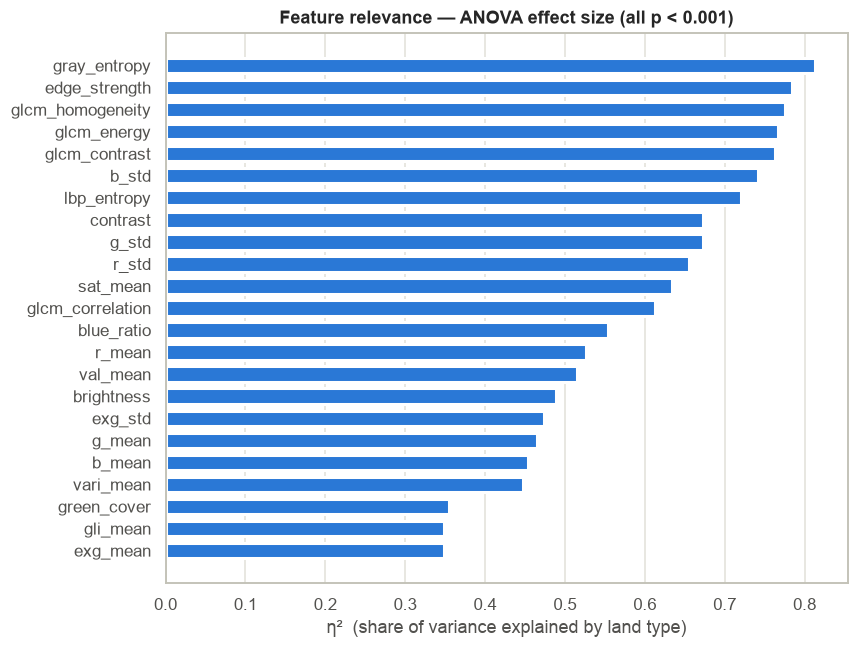

,feature,ANOVA_F,ANOVA_p,Kruskal_H,Kruskal_p,eta_sq
0,gray_entropy,9131.4680,0.0,13607.2960,0.0,0.8131
1,edge_strength,7615.5689,0.0,14853.5548,0.0,0.7839
2,glcm_homogeneity,7252.7656,0.0,14804.8247,0.0,0.7756
3,glcm_energy,6879.7902,0.0,14199.4175,0.0,0.7662
4,glcm_contrast,6737.4692,0.0,14507.4524,0.0,0.7625
5,b_std,6037.0756,0.0,13676.1990,0.0,0.7420
6,lbp_entropy,5416.1703,0.0,11474.5135,0.0,0.7207
7,contrast,4315.9370,0.0,13357.1473,0.0,0.6728
8,g_std,4312.8924,0.0,13212.8457,0.0,0.6727
9,r_std,3984.6132,0.0,13342.1204,0.0,0.6550


In [16]:
rows = []
ztr, ytr = Z[tr], df.loc[tr, "cls"].values
for f in FEATS:
    groups = [ztr.loc[ytr == c, f].values for c in CLASSES]
    Fstat, p = stats.f_oneway(*groups)
    H, pk = stats.kruskal(*groups)
    allv = ztr[f].values
    ss_between = sum(len(g) * (g.mean() - allv.mean()) ** 2 for g in groups)
    eta2 = ss_between / ((allv - allv.mean()) ** 2).sum()
    rows.append({"feature": f, "ANOVA_F": Fstat, "ANOVA_p": p, "Kruskal_H": H, "Kruskal_p": pk, "eta_sq": eta2})
anova = pd.DataFrame(rows).sort_values("eta_sq", ascending=False).reset_index(drop=True)
anova.to_csv(TAB_DIR / "anova_kruskal.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(anova["feature"], anova["eta_sq"], color=BLUE, height=0.7, edgecolor="white", linewidth=2)
ax.invert_yaxis(); ax.set_xlabel("η²  (share of variance explained by land type)")
ax.grid(axis="y", visible=False)
ax.set_title("Feature relevance — ANOVA effect size (all p < 0.001)" if (anova["ANOVA_p"] < 1e-3).all()
             else "Feature relevance — ANOVA effect size")
save(fig, "08_anova_effect_size")
anova.head(10).round(4)

### Pairwise tests on the confusing agricultural pairs (Welch t-test)
The model's hardest job is separating similar vegetation classes. Which features still differ?

In [17]:
pairs = [("AnnualCrop", "PermanentCrop"), ("Pasture", "HerbaceousVegetation"), ("AnnualCrop", "Pasture")]
top = anova["feature"].head(8).tolist()
res = []
for a, b in pairs:
    for f in top:
        va_, vb_ = ztr.loc[ytr == a, f], ztr.loc[ytr == b, f]
        t, p = stats.ttest_ind(va_, vb_, equal_var=False)
        d = (va_.mean() - vb_.mean()) / np.sqrt((va_.var() + vb_.var()) / 2)   # Cohen's d
        res.append({"pair": f"{a} vs {b}", "feature": f, "t": t, "p": p, "cohens_d": d})
tt = pd.DataFrame(res)
tt.to_csv(TAB_DIR / "pairwise_ttests.csv", index=False)
best_per_pair = tt.loc[tt.groupby("pair")["cohens_d"].apply(lambda s: s.abs().idxmax())]
best_per_pair.round(4)

,pair,feature,t,p,cohens_d
23,AnnualCrop vs Pasture,contrast,61.7373,0.0,1.9492
2,AnnualCrop vs PermanentCrop,glcm_homogeneity,61.3057,0.0,2.0132
11,Pasture vs HerbaceousVegetation,glcm_energy,41.9062,0.0,1.3771


### Chi-squared test — vegetation-cover band vs. land type
Is the engineered *Low / Medium / High* vegetation band associated with land type?

chi² = 7,149, dof = 18, p = 0.00e+00, Cramér's V = 0.43


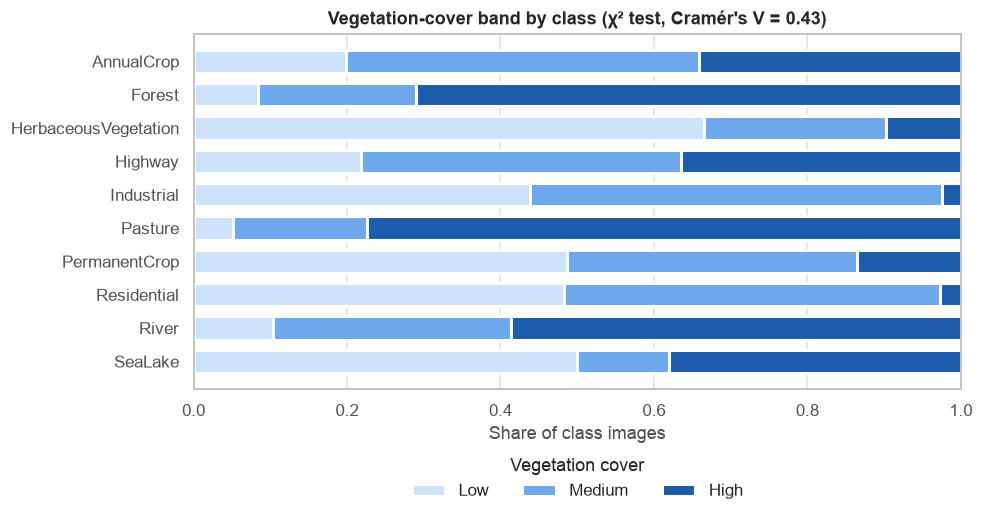

In [18]:
ct = pd.crosstab(df.loc[tr, "cls"], df.loc[tr, "veg_band"]).loc[CLASSES]
chi2, p, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f"chi² = {chi2:,.0f}, dof = {dof}, p = {p:.2e}, Cramér's V = {cramers_v:.2f}")

share = ct.div(ct.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(9, 4.2))
left = np.zeros(len(share))
for band, col in zip(["Low", "Medium", "High"], ["#cde2fb", "#6da7ec", "#1c5cab"]):
    ax.barh(share.index, share[band], left=left, color=col, height=0.7, edgecolor="white", linewidth=2, label=band)
    left += share[band].values
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("Share of class images")
ax.grid(axis="y", visible=False)
ax.legend(title="Vegetation cover", ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15))
ax.set_title(f"Vegetation-cover band by class (χ² test, Cramér's V = {cramers_v:.2f})")
save(fig, "09_vegetation_band_chi2")

## B4. Correlation analysis — removing redundant features
Highly correlated features carry the same information twice. For every pair with
|r| > 0.90 we drop the one with the lower ANOVA effect size.

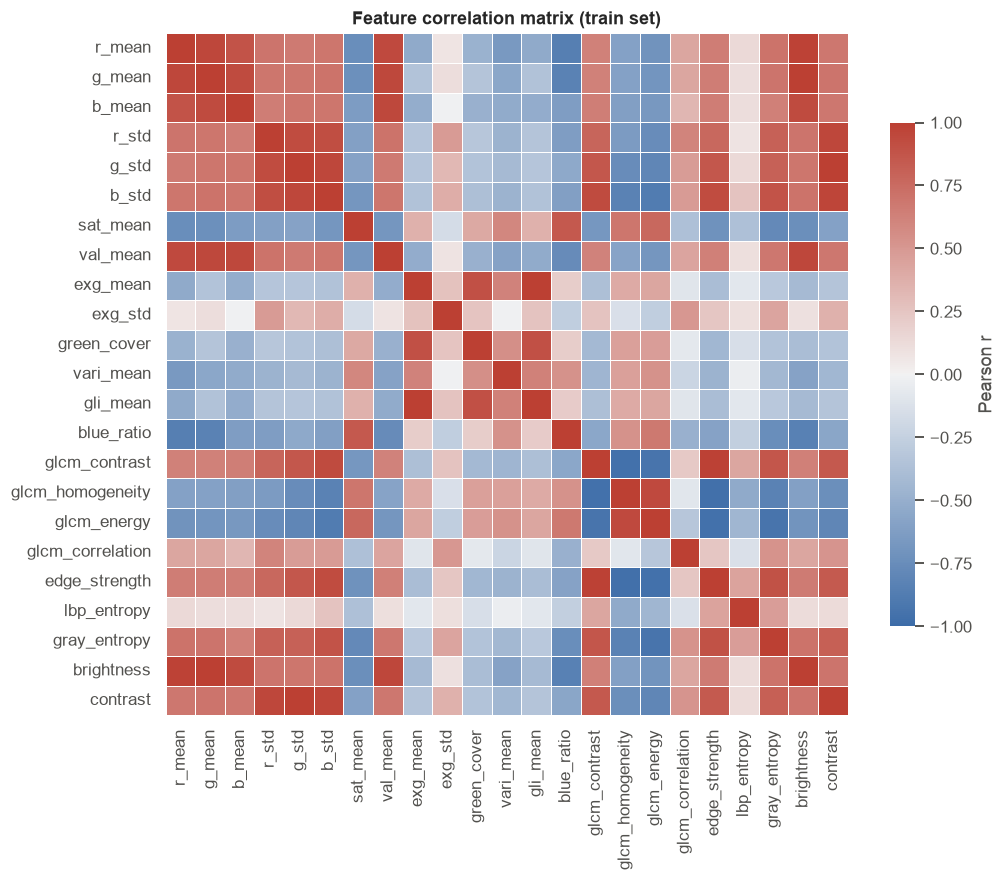

27 pairs with |r| > 0.90 → dropping 12: ['b_mean', 'b_std', 'brightness', 'contrast', 'exg_mean', 'g_mean', 'g_std', 'glcm_contrast', 'glcm_energy', 'glcm_homogeneity', 'gli_mean', 'val_mean']
11 features kept


,feature_a,feature_b,r
18,exg_mean,gli_mean,1.000
5,g_mean,brightness,0.996
12,g_std,contrast,0.995
22,glcm_contrast,edge_strength,0.989
2,r_mean,brightness,0.978
24,glcm_homogeneity,edge_strength,-0.969
15,b_std,contrast,0.963
16,val_mean,brightness,0.960
10,r_std,contrast,0.960
11,g_std,b_std,0.959


In [19]:
corr = Z[tr].corr()
fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(corr, cmap=sns.diverging_palette(250, 15, s=75, l=45, center="light", as_cmap=True),
            vmin=-1, vmax=1, square=True, linewidths=0.5, linecolor="white",
            cbar_kws={"shrink": 0.7, "label": "Pearson r"}, ax=ax)
ax.set_title("Feature correlation matrix (train set)")
save(fig, "10_correlation_heatmap")

eta = anova.set_index("feature")["eta_sq"]
high = [(a, b, corr.loc[a, b]) for i, a in enumerate(FEATS) for b in FEATS[i+1:] if abs(corr.loc[a, b]) > 0.90]
drop = set()
for a, b, r in sorted(high, key=lambda t: -abs(t[2])):
    if a in drop or b in drop: continue
    drop.add(a if eta[a] < eta[b] else b)
KEEP = [f for f in FEATS if f not in drop]
print(f"{len(high)} pairs with |r| > 0.90 → dropping {len(drop)}: {sorted(drop)}")
print(f"{len(KEEP)} features kept")
pd.DataFrame(high, columns=["feature_a", "feature_b", "r"]).sort_values("r", key=abs, ascending=False).round(3)

## B5. Feature selection — mutual information & recursive feature elimination (RFE)
- **Mutual information**: how much knowing a feature reduces uncertainty about the class
  (captures non-linear relationships that ANOVA misses).
- **RFE** with logistic regression: repeatedly drops the weakest feature and keeps the best subset.

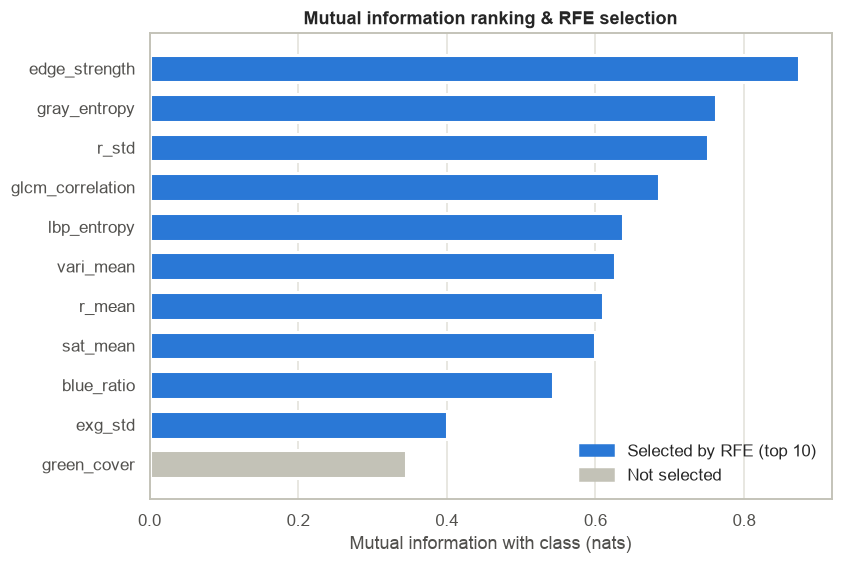

RFE-selected features: ['r_mean', 'r_std', 'sat_mean', 'exg_std', 'vari_mean', 'blue_ratio', 'glcm_correlation', 'edge_strength', 'lbp_entropy', 'gray_entropy']


In [20]:
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression

mi = pd.Series(mutual_info_classif(Z.loc[tr, KEEP], df.loc[tr, "label"], random_state=SEED),
               index=KEEP).sort_values(ascending=False)
N_SELECT = 10
rfe = RFE(LogisticRegression(max_iter=2000), n_features_to_select=N_SELECT).fit(Z.loc[tr, KEEP], df.loc[tr, "label"])
SELECTED = [f for f, s in zip(KEEP, rfe.support_) if s]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(mi.index, mi.values, color=[BLUE if f in SELECTED else GRAY for f in mi.index],
        height=0.7, edgecolor="white", linewidth=2)
ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.set_xlabel("Mutual information with class (nats)")
ax.legend(handles=[Patch(color=BLUE, label=f"Selected by RFE (top {N_SELECT})"), Patch(color=GRAY, label="Not selected")],
          frameon=False, loc="lower right")
ax.set_title("Mutual information ranking & RFE selection")
save(fig, "11_mutual_info_rfe")
print("RFE-selected features:", SELECTED)

## B6. Dimensionality reduction — PCA
How many independent directions do our features really have, and do classes form clusters?

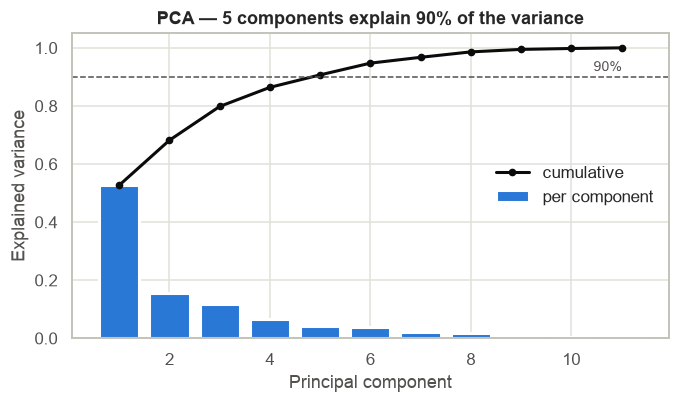

Top PC1 loadings: ['gray_entropy', 'sat_mean', 'r_mean', 'blue_ratio']
Top PC2 loadings: ['exg_std', 'green_cover', 'glcm_correlation', 'vari_mean']


In [21]:
from sklearn.decomposition import PCA
pca = PCA().fit(Z.loc[tr, KEEP])
cum = np.cumsum(pca.explained_variance_ratio_)
n90 = int(np.searchsorted(cum, 0.90) + 1)
P = pca.transform(Z[KEEP])[:, :2]

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(range(1, len(cum) + 1), pca.explained_variance_ratio_, color=BLUE, edgecolor="white", linewidth=2, label="per component")
ax.plot(range(1, len(cum) + 1), cum, color=INK, linewidth=2, marker="o", markersize=4, label="cumulative")
ax.axhline(0.90, color=INK2, linestyle="--", linewidth=1)
ax.text(len(cum), 0.92, "90%", ha="right", color=INK2, fontsize=9)
ax.set_xlabel("Principal component"); ax.set_ylabel("Explained variance"); ax.set_ylim(0, 1.05)
ax.legend(frameon=False, loc="center right"); ax.set_title(f"PCA — {n90} components explain 90% of the variance")
save(fig, "12_pca_variance")

loadings = pd.DataFrame(pca.components_[:2].T, index=KEEP, columns=["PC1", "PC2"])
print("Top PC1 loadings:", loadings["PC1"].abs().sort_values(ascending=False).head(4).index.tolist())
print("Top PC2 loadings:", loadings["PC2"].abs().sort_values(ascending=False).head(4).index.tolist())

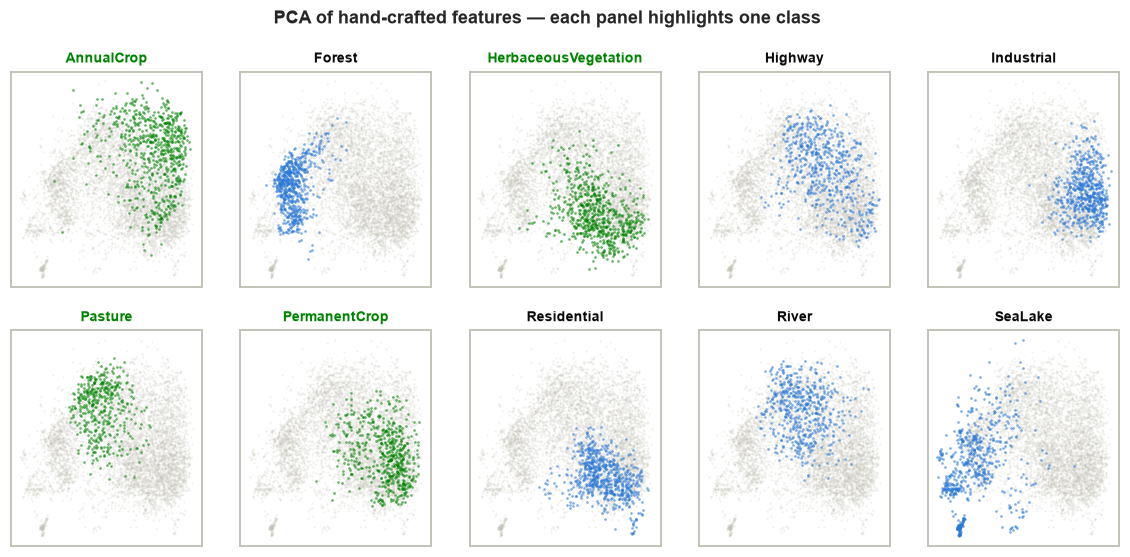

In [22]:
def small_multiples(emb, title, name, sample=None):
    sel = np.arange(len(emb)) if sample is None else sample
    fig, axes = plt.subplots(2, 5, figsize=(13, 5.6), sharex=True, sharey=True)
    cls = df["cls"].values[sel]
    for ax, c in zip(axes.flat, CLASSES):
        m = cls == c
        ax.scatter(emb[sel][~m, 0], emb[sel][~m, 1], s=2, c=GRAY, alpha=0.25, linewidths=0, rasterized=True)
        ax.scatter(emb[sel][m, 0], emb[sel][m, 1], s=3, c=GREEN if c in AGRI else BLUE, alpha=0.6, linewidths=0, rasterized=True)
        ax.set_title(c, fontsize=9, color=GREEN if c in AGRI else INK, fontweight="bold")
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(title, fontweight="bold")
    save(fig, name)

pca_sample = rng.choice(len(P), 6000, replace=False)
small_multiples(P, "PCA of hand-crafted features — each panel highlights one class", "13_pca_scatter", pca_sample)

## B7. Learned features — pretrained ResNet-18 embeddings
Hand-crafted features are interpretable, but a CNN pretrained on ImageNet has learned rich
generic visual features. We pass each image through ResNet-18 (no training, classification
head removed) and keep its **512-dimensional embedding**. This is the bridge to the
transfer-learning model of the next milestone.

In [23]:
from torchvision.models import resnet18, ResNet18_Weights
backbone = resnet18(weights=ResNet18_Weights.DEFAULT, progress=False)
backbone.fc = torch.nn.Identity()
backbone = backbone.eval().to(DEVICE)
IMNET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
IMNET_STD  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

t0, E, BS = time.time(), [], 256
with torch.inference_mode():
    for s in range(0, len(X), BS):
        xb = torch.from_numpy(X[s:s+BS]).to(DEVICE).permute(0, 3, 1, 2).float() / 255.0
        xb = torch.nn.functional.interpolate(xb, size=224, mode="bilinear", align_corners=False)
        E.append(backbone((xb - IMNET_MEAN) / IMNET_STD).cpu().numpy())
E = np.concatenate(E).astype(np.float32)
np.save(TAB_DIR.parent / "resnet18_embeddings.npy", E.astype(np.float16))
print(f"Embeddings {E.shape} in {time.time()-t0:.0f}s on {DEVICE}")

Embeddings (27000, 512) in 104s on mps


t-SNE done in 23s


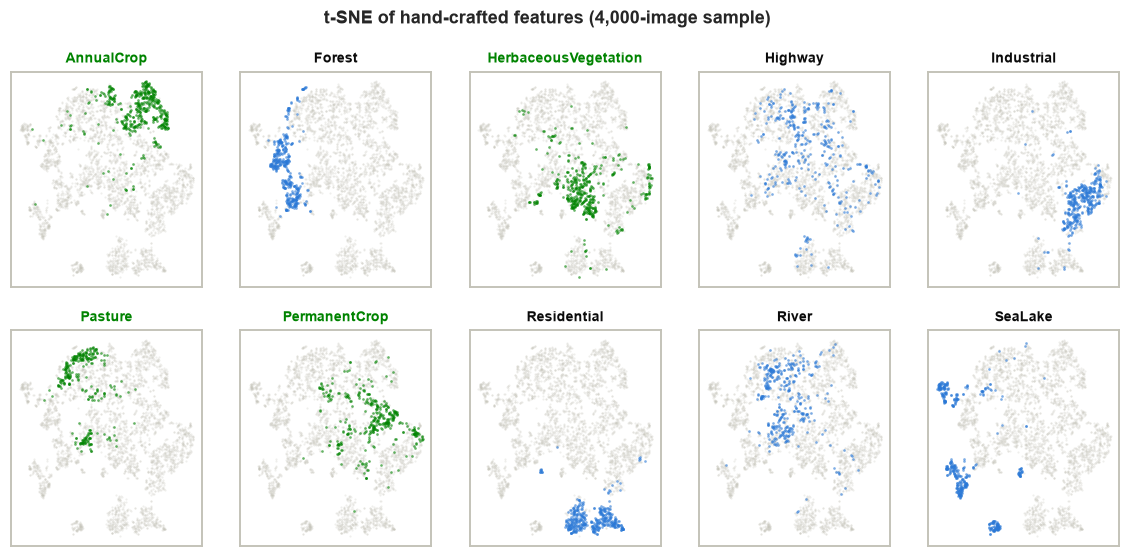

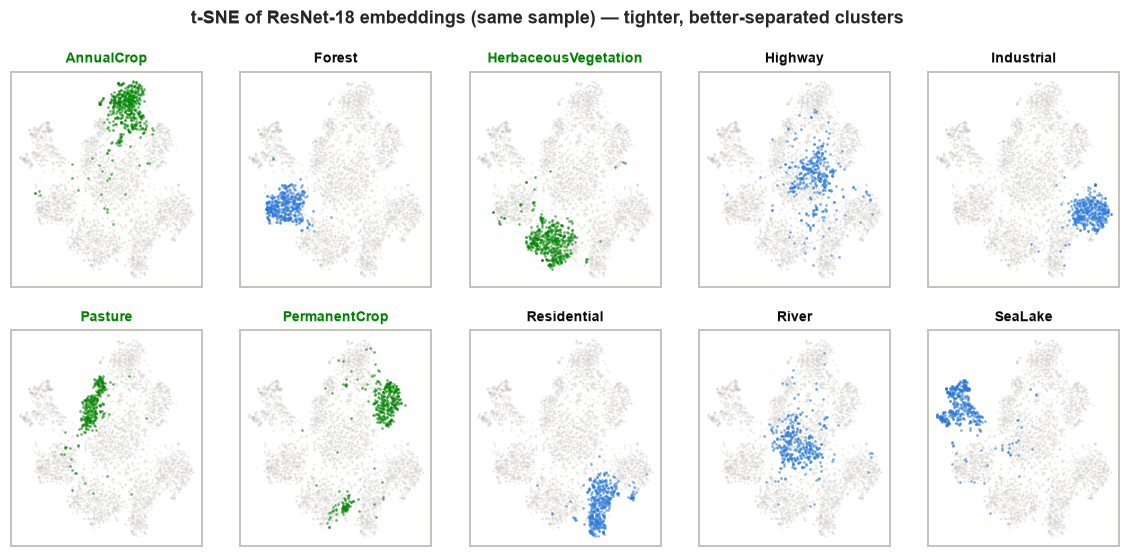

In [24]:
from sklearn.manifold import TSNE
ts_idx = rng.choice(len(df), 4000, replace=False)
t0 = time.time()
tsne_hand = TSNE(perplexity=35, init="pca", random_state=SEED).fit_transform(Z.loc[ts_idx, KEEP].values)
E_s = StandardScaler().fit(E[tr]).transform(E)
tsne_deep = TSNE(perplexity=35, init="pca", random_state=SEED).fit_transform(PCA(50, random_state=SEED).fit_transform(E_s[ts_idx]))
print(f"t-SNE done in {time.time()-t0:.0f}s")

def tsne_full(emb_s):
    full = np.full((len(df), 2), np.nan); full[ts_idx] = emb_s; return full
small_multiples(tsne_full(tsne_hand), "t-SNE of hand-crafted features (4,000-image sample)", "14_tsne_handcrafted", ts_idx)
small_multiples(tsne_full(tsne_deep), "t-SNE of ResNet-18 embeddings (same sample) — tighter, better-separated clusters", "15_tsne_resnet", ts_idx)

## B8. Expected impact on model performance
To quantify what each feature set is worth, we fit the **same simple classifier** (logistic
regression) on each one, train on *train*, score on *validation*. The test set stays untouched
for the final model. This is not the final model — it is a fair, controlled comparison of
inputs.

In [25]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

ytr_l, yva_l = df.loc[tr, "label"].values, df.loc[va, "label"].values
small = X.reshape(len(X), 64 // 4, 4, 64 // 4, 4, 3).mean(axis=(2, 4)).reshape(len(X), -1) / 255.0   # 16×16 RGB
small_s = StandardScaler().fit(small[tr]).transform(small)

feature_sets = {
    "Raw pixels (16×16 RGB)": small_s,
    "Color only (8)": Z[["r_mean", "g_mean", "b_mean", "r_std", "g_std", "b_std", "sat_mean", "val_mean"]].values,
    f"Hand-crafted, all ({len(FEATS)})": Z[FEATS].values,
    f"Hand-crafted, RFE-selected ({N_SELECT})": Z[SELECTED].values,
    "ResNet-18 embeddings (512)": E_s,
}
results, preds = [], {}
for name, M in feature_sets.items():
    t0 = time.time()
    clf = LogisticRegression(max_iter=3000, C=1.0).fit(M[tr], ytr_l)
    p = clf.predict(M[va]); preds[name] = p
    results.append({"feature set": name, "n_features": M.shape[1], "val_accuracy": accuracy_score(yva_l, p),
                    "val_macro_F1": f1_score(yva_l, p, average="macro"), "fit_s": time.time() - t0})
rf = RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=SEED).fit(Z.loc[tr, FEATS], ytr_l)
p = rf.predict(Z.loc[va, FEATS]); preds["Hand-crafted + Random Forest"] = p
results.append({"feature set": "Hand-crafted + Random Forest", "n_features": len(FEATS),
                "val_accuracy": accuracy_score(yva_l, p), "val_macro_F1": f1_score(yva_l, p, average="macro"), "fit_s": np.nan})
res = pd.DataFrame(results)
res.to_csv(TAB_DIR / "feature_set_comparison.csv", index=False)
res.round(3)

,feature set,n_features,val_accuracy,val_macro_F1,fit_s
0,Raw pixels (16×16 RGB),768,0.434,0.430,18.814
1,Color only (8),8,0.686,0.675,0.263
2,"Hand-crafted, all (23)",23,0.838,0.828,0.254
3,"Hand-crafted, RFE-selected (10)",10,0.786,0.770,0.135
4,ResNet-18 embeddings (512),512,0.925,0.922,0.483
5,Hand-crafted + Random Forest,23,0.867,0.858,NaN


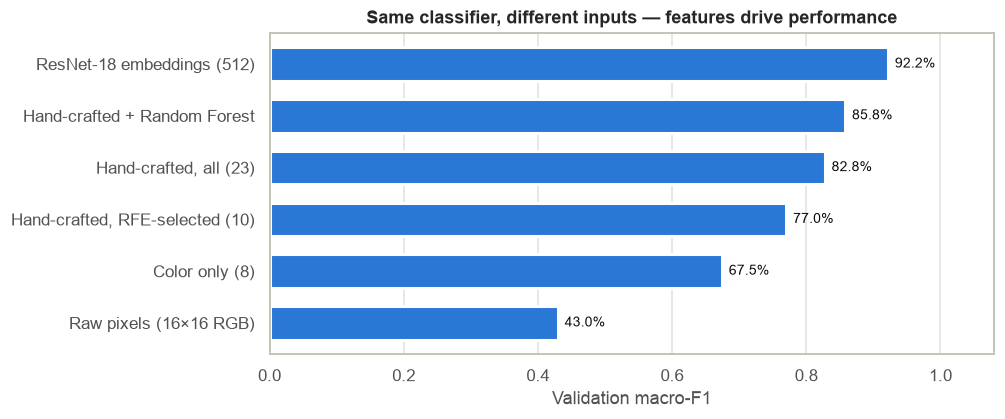

In [26]:
r = res.sort_values("val_macro_F1")
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.barh(r["feature set"], r["val_macro_F1"], color=BLUE, height=0.65, edgecolor="white", linewidth=2)
for y, v in enumerate(r["val_macro_F1"]):
    ax.text(v + 0.01, y, f"{v:.1%}", va="center", color=INK, fontsize=9)
ax.set_xlim(0, 1.08); ax.set_xlabel("Validation macro-F1"); ax.grid(axis="y", visible=False)
ax.set_title("Same classifier, different inputs — features drive performance")
save(fig, "16_feature_set_comparison")

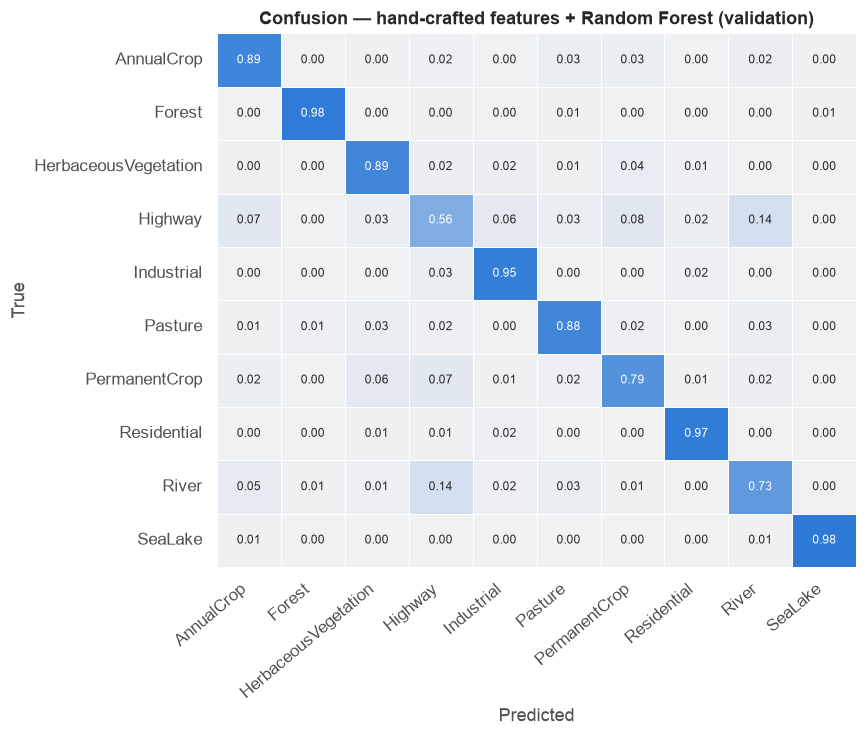

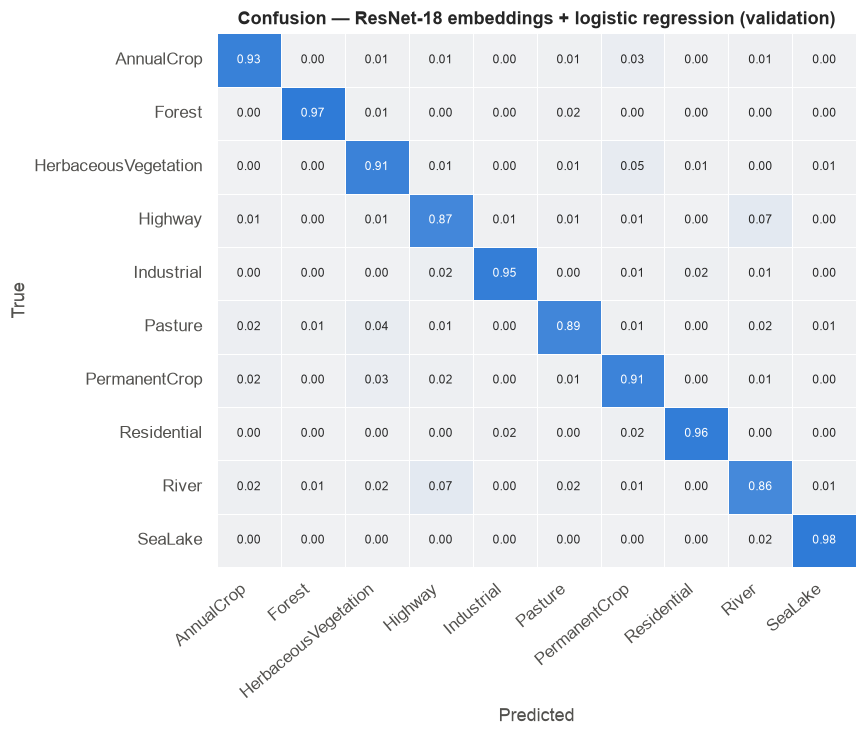

Most confused (hand-crafted):


,true,predicted,rate
0,River,Highway,0.144
1,Highway,River,0.144
2,Highway,PermanentCrop,0.080
3,PermanentCrop,Highway,0.075
4,Highway,AnnualCrop,0.072


Most confused (ResNet-18):


,true,predicted,rate
0,Highway,River,0.069
1,River,Highway,0.067
2,HerbaceousVegetation,PermanentCrop,0.047
3,Pasture,HerbaceousVegetation,0.040
4,PermanentCrop,HerbaceousVegetation,0.032


In [27]:
def plot_cm(y_true, y_pred, title, name):
    cm = confusion_matrix(y_true, y_pred, normalize="true")
    fig, ax = plt.subplots(figsize=(7.5, 6.3))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap=sns.light_palette(BLUE, as_cmap=True), vmin=0, vmax=1,
                xticklabels=CLASSES, yticklabels=CLASSES, cbar=False, linewidths=0.5, linecolor="white",
                annot_kws={"fontsize": 8}, ax=ax)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
    save(fig, name)
    return pd.DataFrame(cm, index=CLASSES, columns=CLASSES)

cm_hand = plot_cm(yva_l, preds["Hand-crafted + Random Forest"], "Confusion — hand-crafted features + Random Forest (validation)", "17_confusion_handcrafted")
cm_deep = plot_cm(yva_l, preds["ResNet-18 embeddings (512)"], "Confusion — ResNet-18 embeddings + logistic regression (validation)", "18_confusion_resnet")

def top_confusions(cm, k=5):
    off = cm.where(~np.eye(len(cm), dtype=bool)).stack().sort_values(ascending=False)
    return off.head(k).rename("rate").reset_index().rename(columns={"level_0": "true", "level_1": "predicted"})
print("Most confused (hand-crafted):"); display(top_confusions(cm_hand).round(3))
print("Most confused (ResNet-18):");    display(top_confusions(cm_deep).round(3))

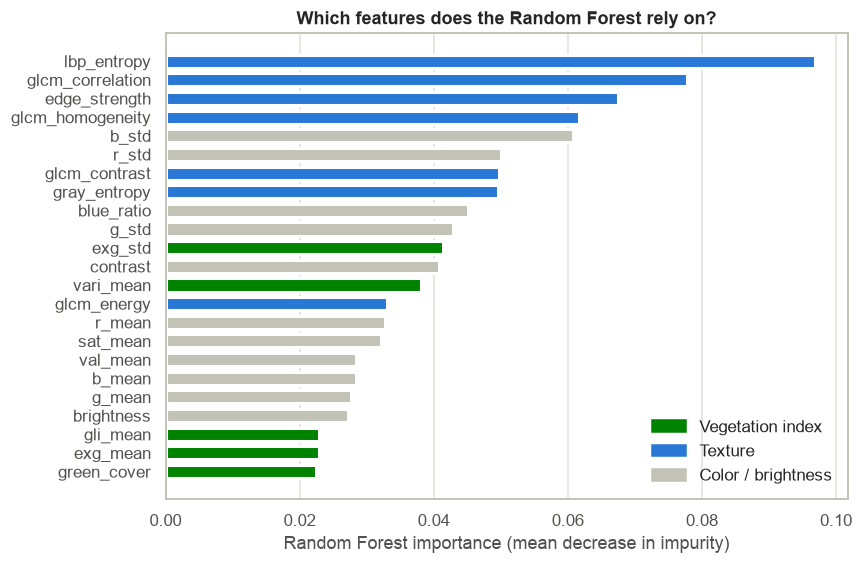

Texture               0.436
Color / brightness    0.416
Vegetation index      0.148
dtype: float64

In [28]:
imp = pd.Series(rf.feature_importances_, index=FEATS).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5.5))
fam = lambda f: ("Vegetation index" if f in ("exg_mean", "exg_std", "green_cover", "vari_mean", "gli_mean")
                 else "Texture" if f.startswith(("glcm", "lbp", "edge", "gray_ent")) else "Color / brightness")
fam_col = {"Vegetation index": GREEN, "Texture": BLUE, "Color / brightness": GRAY}
ax.barh(imp.index, imp.values, color=[fam_col[fam(f)] for f in imp.index], height=0.7, edgecolor="white", linewidth=2)
ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.set_xlabel("Random Forest importance (mean decrease in impurity)")
ax.legend(handles=[Patch(color=v, label=k) for k, v in fam_col.items()], frameon=False, loc="lower right")
ax.set_title("Which features does the Random Forest rely on?")
save(fig, "19_rf_feature_importance")
fam_share = imp.groupby(imp.index.map(fam)).sum().sort_values(ascending=False)
fam_share.round(3)

## B9. Feature engineering summary

In [29]:
RATIONALE = {
    "r_mean": "Red reflectance — high for bare soil / built-up", "g_mean": "Green reflectance — vegetation",
    "b_mean": "Blue reflectance — water, haze", "r_std": "Red variability within tile",
    "g_std": "Green variability — patchy vs. uniform vegetation", "b_std": "Blue variability",
    "sat_mean": "Color saturation — vivid crops vs. gray urban", "val_mean": "HSV value (max channel brightness)",
    "exg_mean": "Excess Green — standard RGB vegetation index", "exg_std": "Vegetation heterogeneity (field patterns)",
    "green_cover": "Fraction of vegetated pixels (ExG > 0.05)", "vari_mean": "VARI — vegetation index robust to atmosphere",
    "gli_mean": "Green Leaf Index", "blue_ratio": "Relative blue — water indicator",
    "glcm_contrast": "Local gray-level contrast (rough vs. smooth)", "glcm_homogeneity": "Texture smoothness — water/pasture high",
    "glcm_energy": "Texture uniformity / repetition", "glcm_correlation": "Linear structure — rows, roads, field edges",
    "edge_strength": "Mean Sobel gradient — edges (roads, buildings)", "lbp_entropy": "Micro-texture diversity (LBP)",
    "gray_entropy": "Information content of the tile", "brightness": "Overall reflectance", "contrast": "Global gray-level spread",
}
summary = (pd.DataFrame({"feature": FEATS})
           .assign(family=lambda d: d["feature"].map(fam), rationale=lambda d: d["feature"].map(RATIONALE),
                   power_transformed=lambda d: d["feature"].isin(POWER_FEATS),
                   eta_sq=lambda d: d["feature"].map(eta).round(3),
                   mutual_info=lambda d: d["feature"].map(mi).round(3),
                   rf_importance=lambda d: d["feature"].map(imp).round(3),
                   dropped_redundant=lambda d: d["feature"].isin(drop),
                   rfe_selected=lambda d: d["feature"].isin(SELECTED))
           .sort_values("eta_sq", ascending=False))
summary.to_csv(TAB_DIR / "feature_engineering_summary.csv", index=False)
summary

,feature,family,rationale,power_transformed,eta_sq,mutual_info,rf_importance,dropped_redundant,rfe_selected
20,gray_entropy,Texture,Information content of the tile,False,0.813,0.762,0.050,False,True
18,edge_strength,Texture,"Mean Sobel gradient — edges (roads, buildings)",True,0.784,0.874,0.067,False,True
15,glcm_homogeneity,Texture,Texture smoothness — water/pasture high,False,0.776,NaN,0.062,True,False
16,glcm_energy,Texture,Texture uniformity / repetition,True,0.766,NaN,0.033,True,False
14,glcm_contrast,Texture,Local gray-level contrast (rough vs. smooth),True,0.762,NaN,0.050,True,False
5,b_std,Color / brightness,Blue variability,True,0.742,NaN,0.061,True,False
19,lbp_entropy,Texture,Micro-texture diversity (LBP),True,0.721,0.637,0.097,False,True
22,contrast,Color / brightness,Global gray-level spread,False,0.673,NaN,0.041,True,False
4,g_std,Color / brightness,Green variability — patchy vs. uniform vegetation,False,0.673,NaN,0.043,True,False
3,r_std,Color / brightness,Red variability within tile,False,0.655,0.751,0.050,False,True


In [30]:
best = res.loc[res["val_macro_F1"].idxmax()]
hand_best = res[res["feature set"].str.startswith("Hand")]["val_macro_F1"].max()
raw = res.loc[res["feature set"].str.startswith("Raw"), "val_macro_F1"].item()
key = {
    "images": len(df), "classes": len(CLASSES),
    "train/val/test": df["split"].value_counts().reindex(["train", "val", "test"]).tolist(),
    "duplicates_removed": int(audit["exact duplicate images"]),
    "handcrafted_features": len(FEATS), "kept_after_correlation": len(KEEP), "rfe_selected": SELECTED,
    "top_eta_features": anova["feature"].head(5).tolist(),
    "pca_components_for_90pct": n90,
    "veg_band_cramers_v": round(float(cramers_v), 3),
    "raw_pixels_F1": round(raw, 3), "best_handcrafted_F1": round(float(hand_best), 3),
    "best_feature_set": best["feature set"], "best_F1": round(float(best["val_macro_F1"]), 3),
}
pd.Series(key).to_json(TAB_DIR / "key_results.json", indent=2)
pd.Series(key, dtype=object).to_frame("value")

,value
images,27000
classes,10
train/val/test,"[18900, 4050, 4050]"
duplicates_removed,0
handcrafted_features,23
kept_after_correlation,11
rfe_selected,"[r_mean, r_std, sat_mean, exg_std, vari_mean, ..."
top_eta_features,"[gray_entropy, edge_strength, glcm_homogeneity..."
pca_components_for_90pct,5
veg_band_cramers_v,0.435


## Key findings

**Data (Milestone 1 redo)**
- 27,000 images, 10 classes, **no corrupt files, no duplicates, no blank tiles** — EuroSAT is clean, so preprocessing is about splitting and normalizing, not repairing.
- Mild imbalance (2,000–3,000 per class, ratio 1.5) → a stratified 70/15/15 split (18,900 / 4,050 / 4,050) is enough.
- Water, forest and pasture are dark and uniform; crops and industry are bright and varied. The four agricultural classes overlap heavily in raw color.

**Feature analysis (Milestone 2)**
1. **Texture beats color.** Texture features have the largest effect sizes (mean η² = 0.75 vs 0.58 for color, 0.40 for vegetation indices). The top 5 features by η² are all texture: gray entropy (0.81), edge strength, GLCM homogeneity, energy, contrast. Fields, forests, water and towns differ more in *pattern* than in *color*.
2. **RGB vegetation indices are the weakest family** (η² 0.35–0.47, 15% of Random Forest importance). EuroSAT's RGB is uncalibrated and hazy, so dark water looks relatively "green" to ExG. → Next step: **NDVI from the near-infrared band** (EuroSAT multispectral, 13 bands).
3. **Even the hardest agricultural pairs are statistically separable** by texture: AnnualCrop vs PermanentCrop on GLCM homogeneity (Cohen's d = 2.0), Pasture vs HerbaceousVegetation on GLCM energy (d = 1.4).
4. **The engineered vegetation-cover band is associated with land type** (χ² = 7,149, p < 0.001, Cramér's V = 0.43 — moderate).
5. **Heavy redundancy:** 27 feature pairs have |r| > 0.90 (e.g. ExG ≡ GLI, r = 1.00). Pruning keeps 11 of 23; PCA needs only **5 components for 90%** of the variance.
6. **Skew fixed:** a Yeo-Johnson power transform brought 8 skewed features from |skew| up to 2.8 down to below 0.3.

**Expected impact on model performance** (same logistic regression, validation macro-F1)

| Input | macro-F1 |
|---|---|
| Raw pixels (16×16) | 43.0% |
| Color only (8 features) | 67.5% |
| RFE-selected (10 features) | 77.0% |
| All hand-crafted (23 features) | 82.8% |
| Hand-crafted + Random Forest | 85.8% |
| **Pretrained ResNet-18 embeddings** | **92.2%** |

- Feature engineering roughly **doubles** performance over raw pixels (43% → 83%).
- RFE trades ~6 points of F1 for 57% fewer features — useful for interpretability, not for accuracy.
- Pretrained CNN features win clearly, without any training on EuroSAT → **Milestone 3 will fine-tune a pretrained CNN (transfer learning)**.
- The remaining error is concentrated in **Highway ↔ River** (both are thin lines through other land: ~14% confused with hand-crafted features, ~7% with ResNet) and among the vegetation classes.
